## Test for cooperation and competition for metabolites

<img src="IMG_3818.png" width="500"/>

In [47]:
import pandas as pd
import numpy as np
import sys

sys.path.append("../functions/")

import compare_inter_exp_sim

In [48]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


**Define example data**

In [50]:
example_dicts = [{"donor":"environment", "receiver":"A","compound":"c1","metric":0.5,"community":"comm1"},
                {"donor":"environment", "receiver":"B","compound":"c1","metric":0.5,"community":"comm1"},
                {"donor":"environment", "receiver":"C","compound":"c2","metric":0.5,"community":"comm1"},
                {"donor":"C", "receiver":"A","compound":"c3","metric":0.5,"community":"comm1"}]
example_sim = pd.DataFrame(example_dicts)

example_sim_dicts = {"example":example_sim}
example_sim_dicts_rec = {"example":example_sim[example_sim.donor!="environment"]}

example_glv = pd.DataFrame([{"donor":"A","receiver":"B","gLV":-1},
                        {"donor":"B","receiver":"A","gLV":-1},
                        {"donor":"B","receiver":"C","gLV":0},
                        {"donor":"C","receiver":"A","gLV":1},
                        {"donor":"A","receiver":"C","gLV":0}])
example_glv =example_glv.set_index(["donor","receiver"])["gLV"]

example_glv = example_glv.reorder_levels(["receiver","donor"])

In [54]:
test,label_dict = compare_inter_exp_sim.coop_or_comp_exp_communities(example_sim_dicts,
                      example_glv,
                      coop_or_comp="comp",
                      metric="metric",
                      sim_thresh =0.01,
                      count_or_sum="count")

In [55]:
test["example"].dropna()

,,gLV,Competition met count - metric
receiver,donor,,
B,A,-1.0,1
A,B,-1.0,1
C,B,0.0,0
A,C,1.0,0
C,A,0.0,0


In [56]:
test,label_dict = compare_inter_exp_sim.coop_or_comp_exp_communities(example_sim_dicts_rec,
                      example_glv,
                      coop_or_comp="coop",
                      metric="metric",
                      sim_thresh =0.01,
                      count_or_sum="count")
test["example"]

,,gLV,Cooperation met count - metric
receiver,donor,,
B,A,-1,NaN
A,B,-1,NaN
C,B,0,NaN
A,C,1,1.0
C,A,0,NaN


In [58]:
test,label_dict = compare_inter_exp_sim.coop_or_comp_exp_communities(example_sim_dicts_rec,
                      example_glv,
                      coop_or_comp="coop",
                      metric="metric",
                      sim_thresh =False,
                      count_or_sum="sum")
test["example"]

,,gLV,Cooperation met sum - metric
receiver,donor,,
B,A,-1,NaN
A,B,-1,NaN
C,B,0,NaN
A,C,1,0.5
C,A,0,NaN


In [59]:
test,label_dict = compare_inter_exp_sim.coop_or_comp_exp_communities(example_sim_dicts,
                      example_glv,
                      coop_or_comp="comp",
                      metric="metric",
                      sim_thresh =False,
                      count_or_sum="sum")
test["example"].dropna()

,,gLV,Competition met sum - metric
receiver,donor,,
B,A,-1.0,0.25
A,B,-1.0,0.25
C,B,0.0,0.00
A,C,1.0,0.00
C,A,0.0,0.00


[INFO] plot_coop_comp_venturelli filters exp_sim_combined (receiver!=donor + exp_sim_combined.dropna())


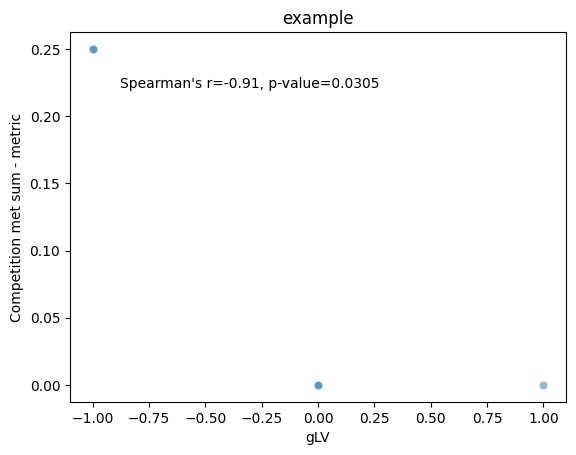

In [66]:
fig,axs = compare_inter_exp_sim.plot_coop_or_comp(test["example"],
                                                  "example",
                                                  label_dict=label_dict)


In [67]:
test,label_dict = compare_inter_exp_sim.coop_or_comp_exp_communities(example_sim_dicts,
                      example_glv,
                      coop_or_comp="coop",
                      metric="metric",
                      sim_thresh =False,
                      count_or_sum="sum")
test["example"].dropna()

,,gLV,Cooperation met sum - metric
receiver,donor,,
A,C,1.0,0.5


[INFO] plot_coop_comp_venturelli filters exp_sim_combined (receiver!=donor + exp_sim_combined.dropna())


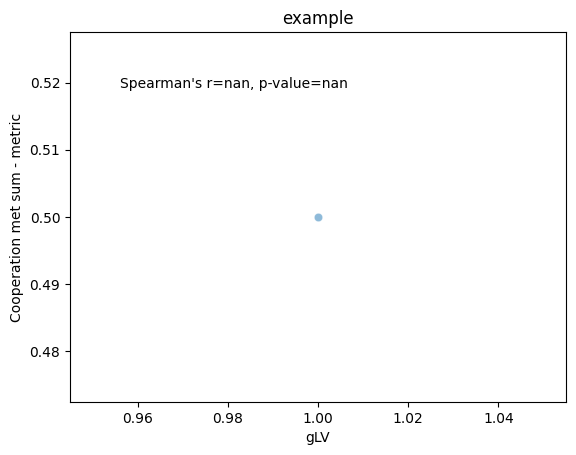

In [68]:
fig,axs = compare_inter_exp_sim.plot_coop_or_comp(test["example"],
                                                  "example",
                                                  label_dict=label_dict)


### Abundances

In [23]:
import abundance_sim_analysis

In [29]:
abundances_example = pd.DataFrame([
    {"sample":1,"member":"A","relative_abundance":0.4,"community":"test"},
    {"sample":1,"member":"B","relative_abundance":0.6,"community":"test"},
    {"sample":2,"member":"A","relative_abundance":1,"community":"test"},
    {"sample":3,"member":"B","relative_abundance":0.3,"community":"test"},
    {"sample":3,"member":"C","relative_abundance":0.7,"community":"test"},
    {"sample":4,"member":"C","relative_abundance":0.4,"community":"test"},
    {"sample":4,"member":"B","relative_abundance":0.6,"community":"test"}])

In [30]:
abundances_example

,sample,member,relative_abundance,community
0,1,A,0.4,test
1,1,B,0.6,test
2,2,A,1.0,test
3,3,B,0.3,test
4,3,C,0.7,test
5,4,C,0.4,test
6,4,B,0.6,test


In [33]:
co_growth_count,member_abund = abundance_sim_analysis.make_co_growth_count_matrix(abundances_example,community="test")

[INFO] Make_co_growth_count_matrix sets diagonal entries (memberA==memberB) to 0.


In [35]:
abundance_sim_analysis.order_co_growth_count(co_growth_count)

['B', 'A', 'C']

<Axes: title={'center': 'test'}, xlabel='member2', ylabel='member1'>

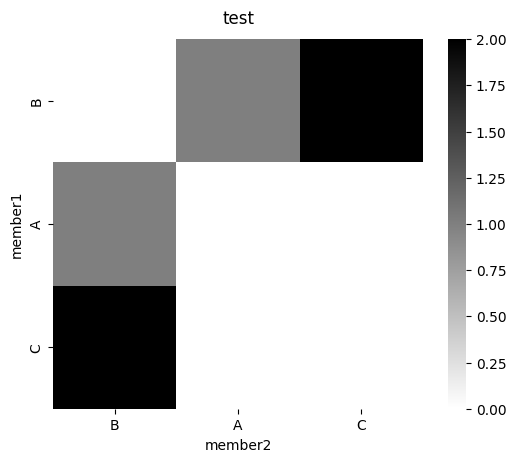

In [39]:


abundance_sim_analysis.plot_co_growth_count(co_growth_count,"test")

<Axes: title={'center': 'test: co_growth'}, xlabel='# members in same sample', ylabel='# samples'>

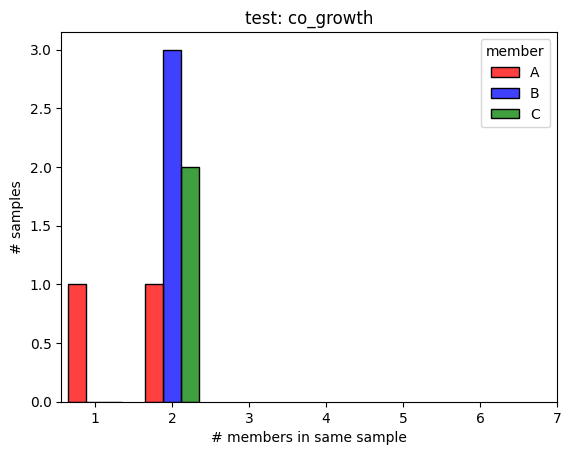

In [43]:
import matplotlib.pyplot as plt

palette = {"A":"red","B":"blue","C":"green"}

fig,ax = plt.subplots(1,1)
abundance_sim_analysis.plot_hist_helper(abundances_example,"test",['A','B','C'],"co_growth",palette,ax)

<Axes: title={'center': 'test: co_growth'}, xlabel='Relative abundance', ylabel='Density'>

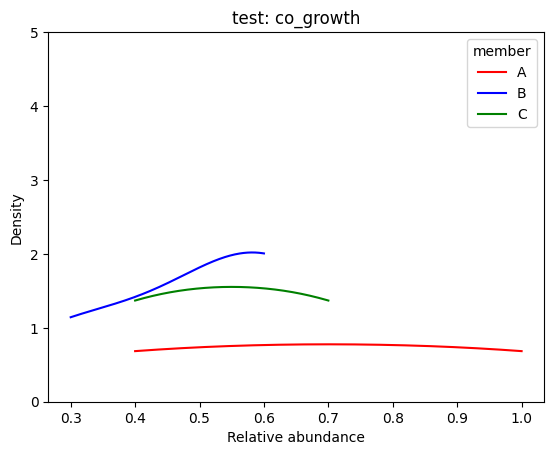

In [44]:
fig,ax = plt.subplots(1,1)
abundance_sim_analysis.plot_density_helper(abundances_example,"test",['A','B','C'],"co_growth",palette,ax)